# 05 – La baseline : le score à battre

## Leçon 1 – Rappel

Une **baseline** est une méthode simple, sans machine learning, qu'on calcule **avant** le modèle. Le modèle n'a d'intérêt que s'il la bat nettement.

Comme dans le projet 13 :
- découpage **temporel** : train 2016-2020 / validation 2021-2022 / test 2023-2025 (**sous clé** jusqu'à la fin) ;
- métrique **PR-AUC** (*average precision*), car les feux sont rares (0,12 % des lignes) : une méthode au hasard obtient une PR-AUC égale au taux de feu ;
- deuxième indicateur, très concret : **quelle part des feux tombe dans les 5 % de lignes jugées les plus risquées ?**

**Baseline principale :** risque = taux de feu historique de la commune pour ce mois (calculé sur le train).

Nouveauté : avec 3 505 communes, beaucoup n'ont **jamais** brûlé pendant le train. Leur taux est 0 → la baseline ne peut pas les départager. On testera donc aussi une variante **lissée** (on « tire » les petits taux vers la moyenne du département).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve

COLONNES = ["code", "dept", "jour", "feu", "mois", "jours_sans_pluie", "bilan_hydrique_30j", "humidite_sol", "log_densite"]
df = pd.read_parquet("../data/processed/features_med.parquet", columns=COLONNES)
df["annee"] = df["jour"].dt.year
print(df.shape)

(12803765, 10)


Avantage du Parquet : on ne lit **que les colonnes nécessaires** (`columns=...`). Lecture en quelques secondes au lieu de tout charger.

In [2]:
train = df[df["annee"] <= 2020]
valid = df[df["annee"].between(2021, 2022)].copy()

for nom, d in [("train", train), ("valid", valid)]:
    print(f"{nom:6} {len(d):>10,} lignes  {d['feu'].sum():>6} feux  taux = {d['feu'].mean():.3%}")

train   6,403,635 lignes    7815 feux  taux = 0.122%
valid   2,558,650 lignes    3452 feux  taux = 0.135%


## Étape 1 – Les baselines simples

In [3]:
resultats = []

def part_feux_couverte(y, score, part=0.05):
    d = pd.DataFrame({"feu": np.asarray(y), "score": np.asarray(score)})
    n = int(len(d) * part)
    return d.sort_values("score", ascending=False).head(n)["feu"].sum() / d["feu"].sum()

def evaluer(nom, y, score):
    pr_auc = average_precision_score(y, score)
    top5 = part_feux_couverte(y, score)
    resultats.append({"méthode": nom, "PR-AUC": round(pr_auc, 4), "top 5 %": round(top5, 3)})
    print(f"{nom:42} PR-AUC = {pr_auc:.4f}   top 5 % → {top5:.0%} des feux")

y = valid["feu"]
evaluer("Constante (aucune information)", y, np.full(len(valid), train["feu"].mean()))
evaluer("Taux par mois", y, valid["mois"].map(train.groupby("mois")["feu"].mean()))
evaluer("Taux par département", y, valid["dept"].map(train.groupby("dept", observed=True)["feu"].mean()).astype(float))
evaluer("Taux par commune", y, valid["code"].map(train.groupby("code")["feu"].mean()))

Constante (aucune information)             PR-AUC = 0.0013   top 5 % → 3% des feux


Taux par mois                              PR-AUC = 0.0023   top 5 % → 11% des feux


Taux par département                       PR-AUC = 0.0038   top 5 % → 25% des feux


Taux par commune                           PR-AUC = 0.0095   top 5 % → 34% des feux


⚠️ La PR-AUC de la constante est ≈ le taux de feu de la validation (0,0013) : c'est le **niveau du hasard**. Son « top 5 % » ne veut rien dire : toutes les lignes ont le même score, donc le tri garde un ordre arbitraire (ici 3 %).

À noter : le taux **par commune** seul atteint déjà 34 % des feux dans le top 5 % : *où* compte énormément.

## Étape 2 – La baseline commune × mois

In [4]:
taux_cm = train.groupby(["code", "mois"])["feu"].mean().rename("score_baseline")
valid = valid.merge(taux_cm, left_on=["code", "mois"], right_index=True, how="left")
print("lignes sans score :", valid["score_baseline"].isna().sum())   # attendu : 0
evaluer("BASELINE : taux commune × mois", y, valid["score_baseline"])

lignes sans score : 0


BASELINE : taux commune × mois             PR-AUC = 0.0130   top 5 % → 32% des feux


## Leçon 2 – Le lissage (ou « shrinkage »)

Problème : une commune de Lozère sans feu en juillet sur 2016-2020 a un taux de **0** (0 feu sur 155 jours). Une commune avec **1** feu a 0,65 %. Sur si peu d'événements, la différence est surtout du **hasard**.

Solution classique (statistique bayésienne, très utilisée en demand planning pour les **nouveaux produits** ou les **petites références**) : on mélange le taux de la commune avec celui d'un groupe plus large, pondéré par la quantité d'information disponible :

$$\text{taux lissé} = \frac{\text{feux de la commune} + k \times \text{taux du département×mois}}{\text{jours de la commune} + k}$$

- si la commune a beaucoup de jours (ou de feux), son propre taux domine ;
- sinon, on se rapproche du taux du département pour ce mois.

`k` est un « nombre de jours fictifs » ; on essaie plusieurs valeurs.

In [5]:
stats_cm = train.groupby(["code", "mois"]).agg(feux=("feu", "sum"), jours=("feu", "size"), dept=("dept", "first"))
taux_dm = train.groupby(["dept", "mois"], observed=True)["feu"].mean().rename("taux_dm")
stats_cm = stats_cm.join(taux_dm, on=["dept", "mois"])

for k in [50, 200, 1000]:
    lisse = ((stats_cm["feux"] + k * stats_cm["taux_dm"]) / (stats_cm["jours"] + k)).rename("lisse")
    score = valid[["code", "mois"]].merge(lisse, left_on=["code", "mois"], right_index=True, how="left")["lisse"]
    evaluer(f"Baseline lissée commune × mois (k={k})", y, score.values)

Baseline lissée commune × mois (k=50)      PR-AUC = 0.0152   top 5 % → 34% des feux


Baseline lissée commune × mois (k=200)     PR-AUC = 0.0157   top 5 % → 33% des feux


Baseline lissée commune × mois (k=1000)    PR-AUC = 0.0138   top 5 % → 30% des feux


## Étape 3 – Une feature météo seule

In [6]:
evaluer("Humidité des sols seule (inversée)", y, -valid["humidite_sol"])
evaluer("Jours sans pluie seuls", y, valid["jours_sans_pluie"])
evaluer("Bilan hydrique 30 j seul (inversé)", y, -valid["bilan_hydrique_30j"])
evaluer("Densité de population seule", y, valid["log_densite"])

Humidité des sols seule (inversée)         PR-AUC = 0.0026   top 5 % → 12% des feux


Jours sans pluie seuls                     PR-AUC = 0.0028   top 5 % → 14% des feux


Bilan hydrique 30 j seul (inversé)         PR-AUC = 0.0035   top 5 % → 19% des feux


Densité de population seule                PR-AUC = 0.0022   top 5 % → 13% des feux


« Inversée » : `average_precision_score` attend un score où **grand = risqué**. Une humidité des sols **basse** est risquée → on prend `-humidite_sol`.

## Étape 4 – Le tableau récapitulatif

In [7]:
tableau = pd.DataFrame(resultats).sort_values("PR-AUC", ascending=False)
tableau["× hasard"] = (tableau["PR-AUC"] / y.mean()).round(1)
tableau

,méthode,PR-AUC,top 5 %,× hasard
6,Baseline lissée commune × mois (k=200),0.0157,0.333,11.6
5,Baseline lissée commune × mois (k=50),0.0152,0.335,11.3
7,Baseline lissée commune × mois (k=1000),0.0138,0.302,10.2
4,BASELINE : taux commune × mois,0.0130,0.321,9.6
3,Taux par commune,0.0095,0.345,7.0
2,Taux par département,0.0038,0.246,2.8
10,Bilan hydrique 30 j seul (inversé),0.0035,0.194,2.6
9,Jours sans pluie seuls,0.0028,0.141,2.1
8,Humidité des sols seule (inversée),0.0026,0.118,1.9
1,Taux par mois,0.0023,0.110,1.7


**Lecture :**
- La baseline **commune × mois** fait **≈ 10× mieux que le hasard** (PR-AUC 0,0130).
- Le **lissage** l'améliore nettement : **0,0157** avec k = 200 (≈ 12× le hasard). Il ne sert pas à être plus « juste » sur les communes connues, mais à mieux **trier les communes peu informées**. Trop lisser (k = 1000) efface l'information propre de chaque commune et dégrade le score : il y a un juste milieu, comme pour tout réglage.
- Les features météo seules font **moins bien** que la baseline. Elles ne savent pas *où* les feux ont lieu, seulement *quand* il fait sec. Le modèle de ML devra combiner les deux.

## Étape 5 – Courbes précision-rappel

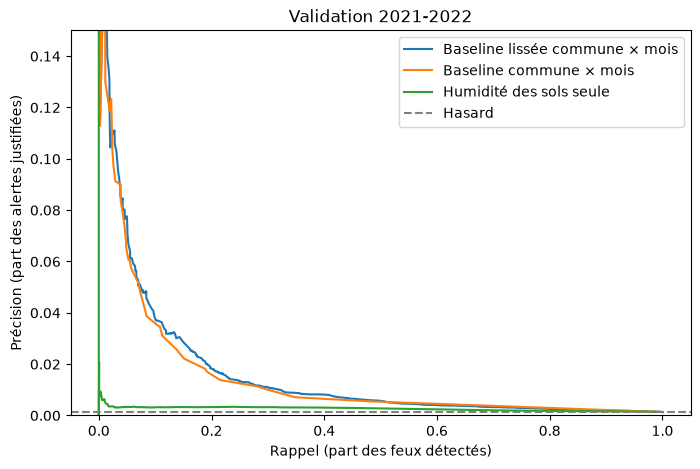

In [8]:
lisse = ((stats_cm["feux"] + 200 * stats_cm["taux_dm"]) / (stats_cm["jours"] + 200)).rename("score_lisse")
valid = valid.merge(lisse, left_on=["code", "mois"], right_index=True, how="left")

plt.figure(figsize=(8, 5))
for nom, score in [
    ("Baseline lissée commune × mois", valid["score_lisse"]),
    ("Baseline commune × mois", valid["score_baseline"]),
    ("Humidité des sols seule", -valid["humidite_sol"]),
]:
    precision, rappel, _ = precision_recall_curve(y, score)
    plt.plot(rappel, precision, label=nom)
plt.axhline(y.mean(), color="grey", linestyle="--", label="Hasard")
plt.xlabel("Rappel (part des feux détectés)")
plt.ylabel("Précision (part des alertes justifiées)")
plt.title("Validation 2021-2022")
plt.ylim(0, 0.15)
plt.legend()
plt.show()

## Étape 6 – La barre à franchir

La baseline retenue est la version **lissée (k = 200)**. Pour être utile, le modèle de ML devra faire mieux que **PR-AUC 0,0157** et **33 % des feux dans le top 5 %** (attendu ci-dessous : 17 % au top 1 %, 33 % au top 5 %, 46 % au top 10 %, 60 % au top 20 %).

In [9]:
for part in [0.01, 0.05, 0.10, 0.20]:
    print(f"Top {part:>4.0%} des lignes → {part_feux_couverte(y, valid['score_lisse'], part):.0%} des feux")
tableau.to_csv("../data/processed/resultats_validation.csv", index=False)

Top   1% des lignes → 17% des feux
Top   5% des lignes → 33% des feux


Top  10% des lignes → 46% des feux


Top  20% des lignes → 60% des feux


## 🎯 À toi de jouer

Calcule la PR-AUC de la baseline lissée **par département** sur la validation. Où est-elle la meilleure ? La pire ?

*(indice : boucle sur `valid["dept"].unique()` et filtre `valid[valid["dept"] == d]`)*

In [10]:
# à toi

<details><summary>Correction</summary>

```python
par_dept = {}
for d in valid["dept"].unique():
    v = valid[valid["dept"] == d]
    par_dept[d] = average_precision_score(v["feu"], v["score_lisse"])
pd.Series(par_dept).sort_values()
```
Attention en comparant : la PR-AUC dépend du **taux de feu** de chaque département (le niveau du hasard n'est pas le même partout).
</details>

## Récap

1. Même protocole que le projet 13 : découpage temporel, PR-AUC, couverture du top 5 %.
2. Baseline commune × mois → **forte**, et encore meilleure **lissée** vers le département (le *shrinkage*, utile dès qu'on a beaucoup de petites séries).
3. Les features météo seules ne battent pas la baseline. Il faut les **combiner** à la géographie.

**Prochaine étape (06) :** comparer plusieurs modèles de machine learning et choisir le meilleur.